### Overview

This script loads preconditioning data from Day 1 and Day 2 for each subject and plots the change in accuracy across runs.

- All subjects completed 3 runs of preconditioning on **Day 1**, although they could complete up to 5 runs (learning was terminated early if they reached a 90% accuracy threshold).  
- Two subjects completed **two runs** on **Day 2**; for them, we used the **last run before scanning** (Run 7) in the analysis.  
- For all other subjects, we used the available Day 2 run (Run 6) and treated it as a continuation (**Run 4**) following Day 1.


In [1]:
import pandas as pd
from pathlib import Path
import matplotlib.pyplot as plt
from IPython.display import Image, display
import seaborn as sns
from scipy.stats import ttest_rel, wilcoxon
from scipy.stats import pearsonr

In [2]:
# load common plot configurations
import plot_config
from plot_config import session_colors

In [3]:
# Base directory
base_path = Path('/Users/liuq13/project-SPCD/beh_processed_subs/')

In [4]:
def load_precond_day(day):
    dfs = []
    for subj_path in base_path.glob('sub-*'):
        file_path = subj_path / f'preconditioning_day{day}_dat.csv'
        if file_path.exists():
            df = pd.read_csv(file_path)
            df['SubID'] = subj_path.name
            df['Day'] = day
            dfs.append(df)
    return pd.concat(dfs, ignore_index=True)

df_day1 = load_precond_day(day=1)
df_day2 = load_precond_day(day=2)


In [5]:
# -- Step 1: Compute Day 1 accuracy per subject per run --
acc_day1 = df_day1.groupby(['SubID', 'run'])['acc'].mean().reset_index()

# -- Step 2: Clean Day 2 and compute subject-wise run 1 accuracy --
# Copy original Day 2 data
df_day2_fixed = df_day2.copy()

# Identify subjects with run 7
has_run7 = df_day2_fixed[df_day2_fixed['run'] == 7]['SubID'].unique()

# Drop run 6 for those subjects
df_day2_fixed = df_day2_fixed[~((df_day2_fixed['SubID'].isin(has_run7)) & (df_day2_fixed['run'] == 6))]

# Rename run 7 → 1, run 6 → 1 for others
df_day2_fixed.loc[
    (df_day2_fixed['SubID'].isin(has_run7)) & (df_day2_fixed['run'] == 7), 'run'
] = 1
df_day2_fixed.loc[df_day2_fixed['run'] == 6, 'run'] = 1

# Compute accuracy for Day 2 run 1
acc_day2_run1 = df_day2_fixed[df_day2_fixed['run'] == 1].groupby('SubID')['acc'].mean().reset_index()
acc_day2_run1['run'] = 4  # Treat as continuation of Day 1

# -- Step 3: Combine Day 1 + Day 2 run 1 data --
acc_all = pd.concat([acc_day1, acc_day2_run1], ignore_index=True)

In [6]:
has_run7

array(['sub-36', 'sub-04'], dtype=object)

In [7]:
EXCLUDE_SUBJECTS = ['sub-19', 'sub-33']
acc_all = acc_all[~acc_all['SubID'].isin(EXCLUDE_SUBJECTS)]
acc_all

,SubID,run,acc
0,sub-01,1.0,0.791667
1,sub-01,2.0,1.000000
2,sub-01,3.0,1.000000
3,sub-02,1.0,1.000000
4,sub-02,2.0,1.000000
...,...,...,...
131,sub-37,4.0,1.000000
132,sub-38,4.0,1.000000
133,sub-39,4.0,0.958333
134,sub-40,4.0,1.000000


In [8]:
summary = (
    acc_all
    .groupby("run")["acc"]
    .agg(["mean", "std", "median", "min", "max", "count"])
)

summary


,mean,std,median,min,max,count
run,,,,,,
1.0,0.803385,0.116048,0.833333,0.458333,1.0,32
2.0,0.980469,0.039577,1.000000,0.833333,1.0,32
3.0,0.988281,0.024213,1.000000,0.916667,1.0,32
4.0,0.986979,0.026852,1.000000,0.916667,1.0,32


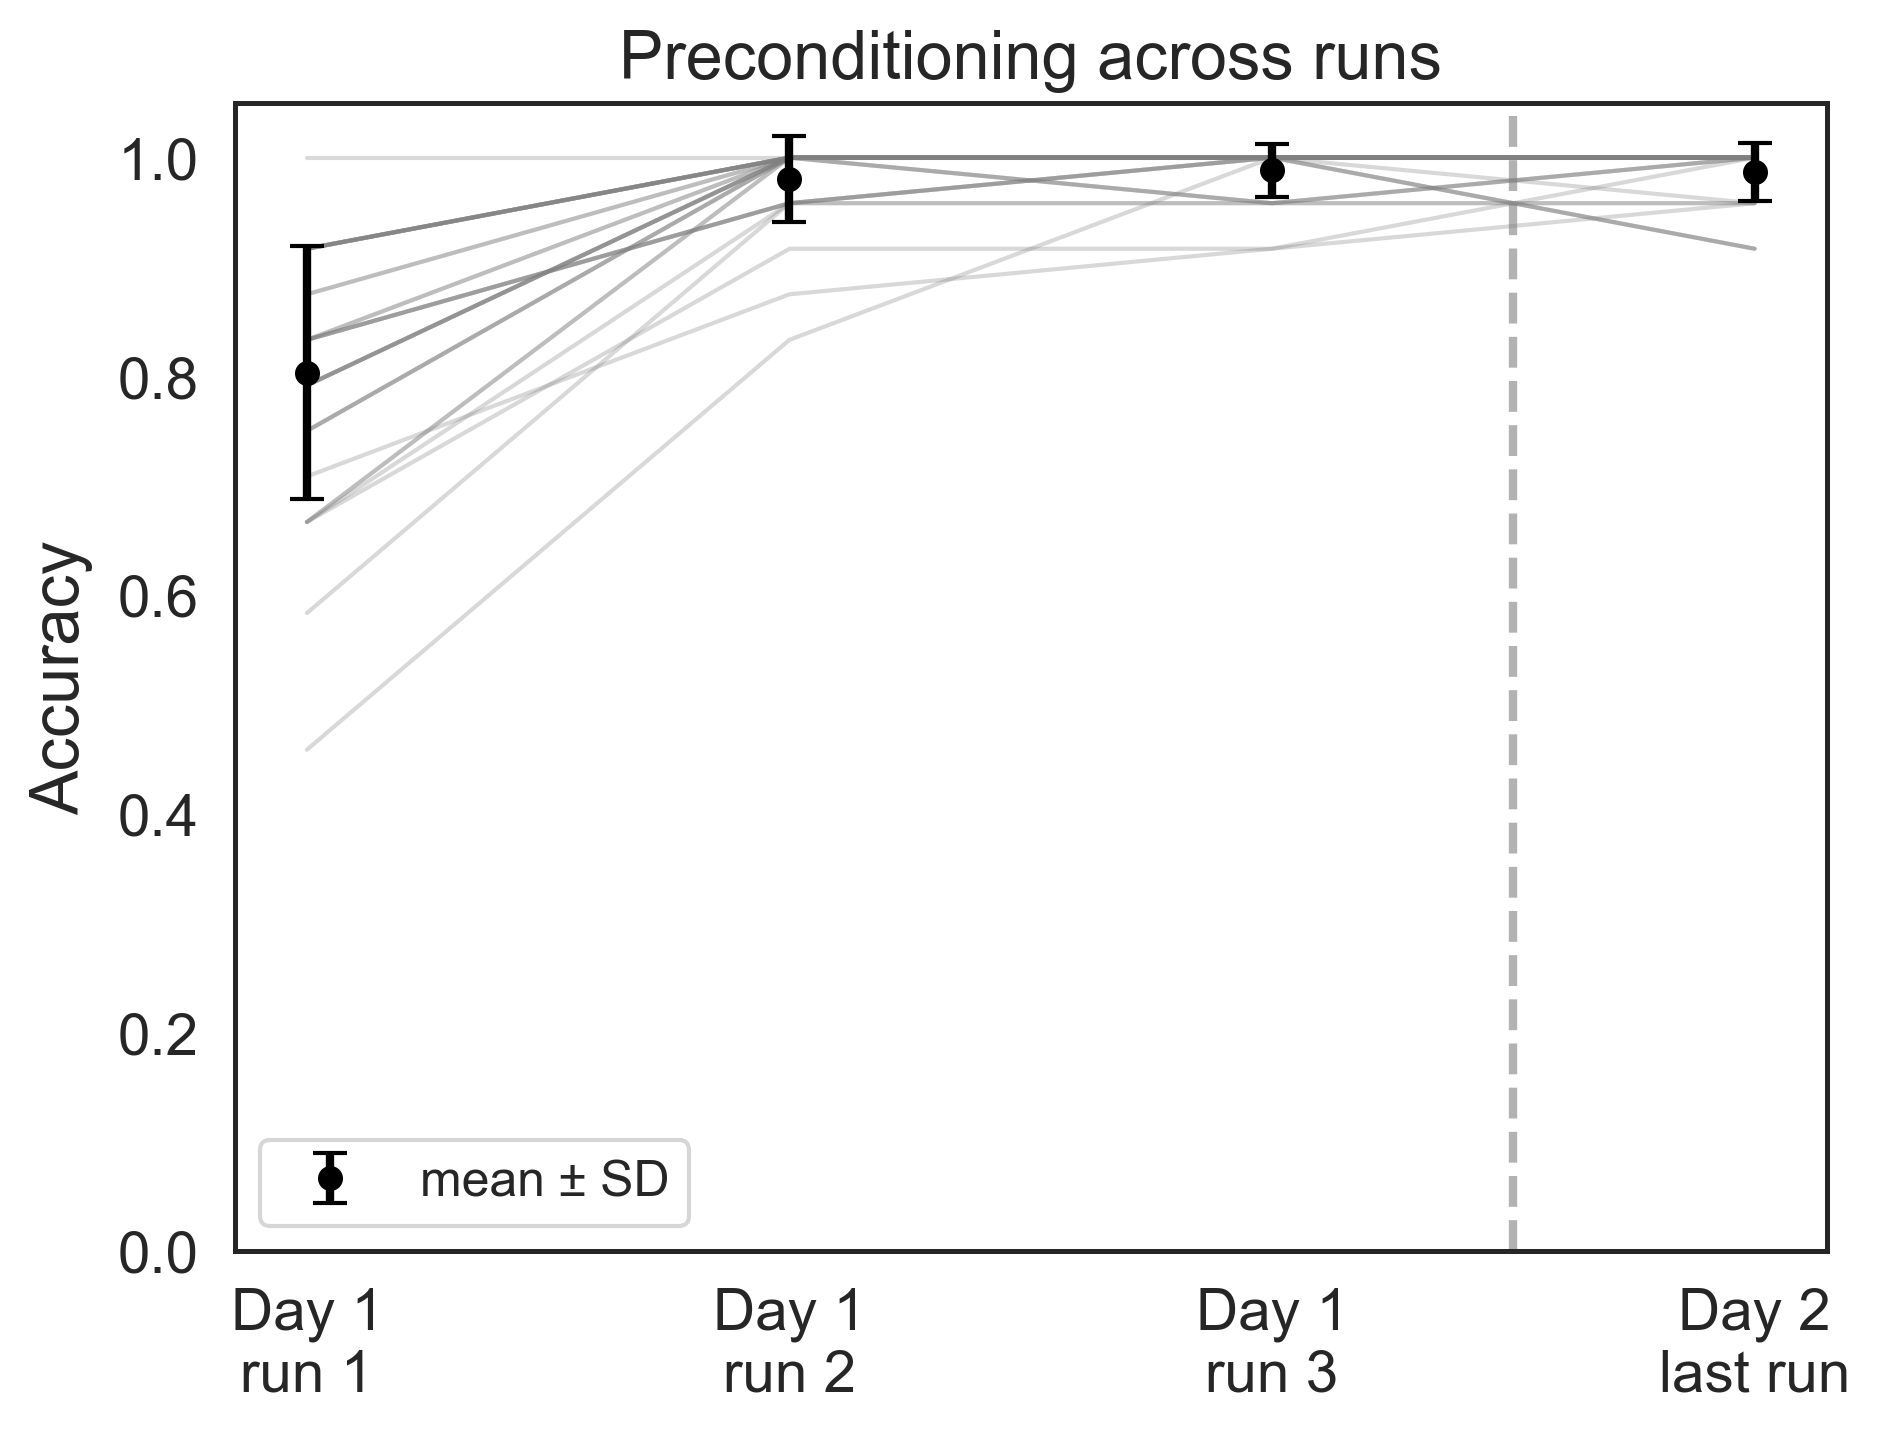

In [15]:
plt.figure(figsize=(6.5, 5))

# Plot individual subject lines
for subid, sub_df in acc_all.groupby('SubID'):
    plt.plot(sub_df['run'], sub_df['acc'], alpha=0.3, linewidth=1, color='gray')

# Plot group mean ± SD
group_stats = acc_all.groupby('run')['acc'].agg(['mean', 'std'])
plt.errorbar(group_stats.index, 
             group_stats['mean'], 
             yerr=group_stats['std'],
             fmt='o', 
             markersize=5,
             capsize=4,
             color='black', linewidth=2, label='mean ± SD')

# Customization
plt.xticks([1, 2, 3, 4],
           ['Day 1\nrun 1', 'Day 1\nrun 2', 'Day 1\nrun 3', 'Day 2\nlast run'])
plt.yticks()
plt.xlabel('')
plt.ylabel('Accuracy')
plt.title('Preconditioning across runs')
plt.axvline(x=3.5, color='gray', linestyle='--', alpha=0.6)
plt.legend()

plt.ylim(0, 1.05)
plt.tight_layout()
plt.savefig('../plots/preconditioning.pdf', format='pdf', bbox_inches='tight')
plt.show()


### Accuracy by Pair Type in the Last Run (Day 2)

This analysis examines accuracy in the final preconditioning run on Day 2 and compares performance across the three pair groups (G1: pairs 1/4, G2: pairs 2/5, G3: pairs 3/6). Accuracy was near ceiling for all groups, and a Friedman test indicated no significant differences among them, suggesting comparable performance across pair types in the last run.


In [16]:
# -- Step 2: Clean Day 2 and compute subject-wise run 1 accuracy --
# Copy original Day 2 data
df_day2_fixed = df_day2.copy()

df_day2_fixed = df_day2_fixed[~df_day2_fixed['SubID'].isin(EXCLUDE_SUBJECTS)]

# Drop run 6 for those subjects
df_day2_fixed = df_day2_fixed[~((df_day2_fixed['SubID'].isin(has_run7)) & (df_day2_fixed['run'] == 6))]

# Rename run 7 → 1, run 6 → 1 for others
df_day2_fixed.loc[
    (df_day2_fixed['SubID'].isin(has_run7)) & (df_day2_fixed['run'] == 7), 'run'
] = 1
df_day2_fixed.loc[df_day2_fixed['run'] == 6, 'run'] = 1

# Compute accuracy for Day 2 run 1
acc_day2_run1 = df_day2_fixed[df_day2_fixed['run'] == 1].groupby(['SubID','pair'])['acc'].mean().reset_index()

In [17]:
acc_day2_run1

,SubID,pair,acc
0,sub-01,1.0,1.0
1,sub-01,2.0,1.0
2,sub-01,3.0,1.0
3,sub-01,4.0,1.0
4,sub-01,5.0,1.0
...,...,...,...
187,sub-41,2.0,1.0
188,sub-41,3.0,1.0
189,sub-41,4.0,1.0
190,sub-41,5.0,1.0


In [18]:
# 1. Define groups
pair_group_map = {
    1: 'A1-B1', 4: 'A1-B1',
    2: 'A2-B2', 5: 'A2-B2',
    3: 'C-D', 6: 'C-D'
}

acc_day2_run1['pair_group'] = acc_day2_run1['pair'].map(pair_group_map)
acc_day2_run1

,SubID,pair,acc,pair_group
0,sub-01,1.0,1.0,A1-B1
1,sub-01,2.0,1.0,A2-B2
2,sub-01,3.0,1.0,C-D
3,sub-01,4.0,1.0,A1-B1
4,sub-01,5.0,1.0,A2-B2
...,...,...,...,...
187,sub-41,2.0,1.0,A2-B2
188,sub-41,3.0,1.0,C-D
189,sub-41,4.0,1.0,A1-B1
190,sub-41,5.0,1.0,A2-B2


In [19]:
# 2. Average acc per subject × group
df_grouped = (
    acc_day2_run1
    .groupby(['SubID', 'pair_group'])['acc']
    .mean()
    .reset_index()
)
df_grouped

,SubID,pair_group,acc
0,sub-01,A1-B1,1.0
1,sub-01,A2-B2,1.0
2,sub-01,C-D,1.0
3,sub-02,A1-B1,1.0
4,sub-02,A2-B2,1.0
...,...,...,...
91,sub-40,A2-B2,1.0
92,sub-40,C-D,1.0
93,sub-41,A1-B1,1.0
94,sub-41,A2-B2,1.0


In [20]:
# 3. Wide format
df_wide = df_grouped.pivot(index='SubID', columns='pair_group', values='acc')
df_wide.shape

(32, 3)

In [21]:
# 4. Friedman test
from scipy.stats import friedmanchisquare
friedmanchisquare(df_wide['A1-B1'], df_wide['A2-B2'], df_wide['C-D'])

FriedmanchisquareResult(statistic=np.float64(0.2857142857142857), pvalue=np.float64(0.8668778997501817))

In [29]:
import pandas as pd
import matplotlib.pyplot as plt

# 1. Average acc per subject within each group
df_grouped = (
    acc_day2_run1
    .groupby(['SubID', 'pair_group'])['acc']
    .mean()
    .reset_index()
)

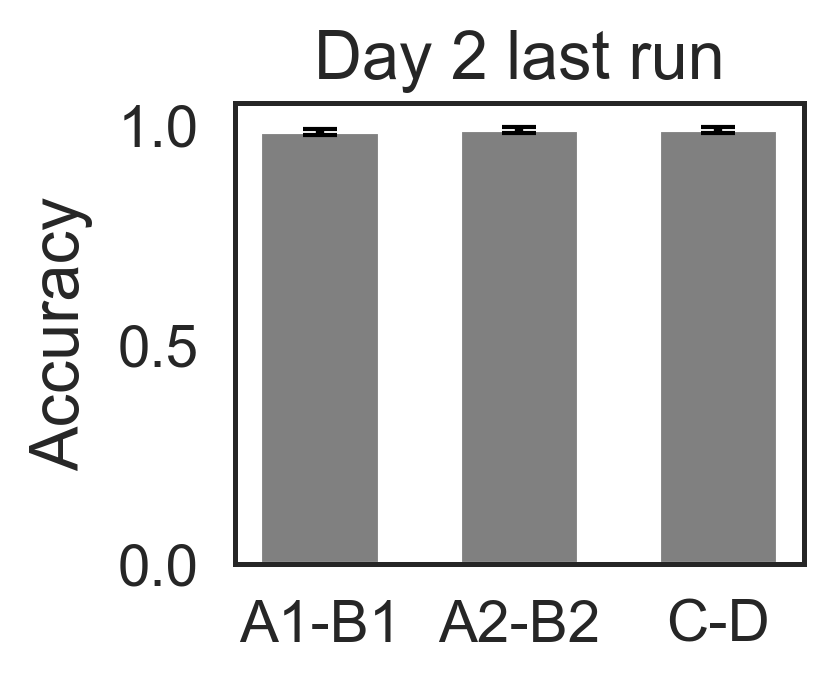

In [34]:
# --- compute group mean + SD (to match ci='sd') ---
summary = (
    df_grouped
    .groupby('pair_group')['acc']
    .agg(['mean', 'sem'])
    .reset_index()
)

x = np.arange(len(summary))

fig, ax = plt.subplots(figsize=(3, 2.5))

ax.bar(
    x,
    summary['mean'],
    yerr=summary['sem'],
    width=0.6,
    capsize=4,
    color='gray'
)

ax.set_xlabel('')
ax.set_ylabel('Accuracy')
ax.set_title('Day 2 last run')
ax.set_ylim(0, 1.05)

ax.set_xticks(x)
ax.set_xticklabels(summary['pair_group'])

plt.tight_layout()
plt.savefig('../plots/preconditioning_end.pdf',
            format='pdf', bbox_inches='tight')
plt.show()
